# 04 · Machine learning: heterogeneous effects (causal forest) and forecasting

The ML component has two parts.

**Part A — Causal forest (main ML contribution).** A causal forest (Wager & Athey, 2018; implemented as `CausalForestDML` in EconML) estimates the effect of IPP capital per worker on the labour share **separately for each industry**. It learns how the effect varies with each industry's *initial characteristics* (1998–2002) and is **never told which industries are in finance**. If banking, securities and insurance land at the negative (labour-substituting) end of the distribution, that is independent, data-driven support for the paper's central finding.

* Outcome *Y*: labour share; treatment *T*: lagged log real IPP capital per worker; both two-way demeaned (industry and year), as in the fixed-effects models.
* Heterogeneity features *X*: initial labour share, IPP and equipment per worker, productivity, real pay, IPP share of capital, industry size and IPP growth, all measured in 1998–2002 and so fixed before the estimation window (2003 onwards).
* Controls *W*: lagged equipment per worker and productivity growth (demeaned).
* Cross-fitting is grouped by industry, so no industry appears in both the training and evaluation folds of the nuisance models.

**Part B — Forecasting (H4).** Out-of-sample forecasts of labour-share changes at **1-year** and **3-year** horizons, with outlier-robust training (targets capped at the training sample's 1st and 99th percentiles; Huber and absolute-error losses). The 1-year results act as a benchmark: notebook 04's first version showed that year-to-year changes are close to unpredictable.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "exgap").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from exgap.build_panel import load_panel
from exgap import stats as st
from exgap.config import RANDOM_STATE
st.set_style()
df = load_panel().sort_values(["code", "year"]).reset_index(drop=True)
g = df.groupby("code")
df["L_ipp"] = g["log_ipp_pw"].shift(1)
df["L_eq"] = g["log_eq_pw"].shift(1)
print(df.code.nunique(), "industries;", df.year.min(), "-", df.year.max())

64 industries; 1997 - 2025


# Part A · Causal forest
## A1. Initial industry characteristics (1998–2002) and estimation sample (2003 onwards)

In [3]:
INIT_YEARS, EST_START = (1998, 2002), 2003
init_vars = {"labor_share": "init_labor_share", "log_ipp_pw": "init_log_ipp_pw", "log_eq_pw": "init_log_eq_pw",
             "log_productivity": "init_log_productivity", "log_pay_real": "init_log_pay_real",
             "ipp_share_of_capital": "init_ipp_share_of_capital", "va_share_of_total": "init_va_share",
             "g_ipp_stock": "init_ipp_growth"}
init_vars = {k: v for k, v in init_vars.items() if k in df}
init = (df[df.year.between(*INIT_YEARS)].groupby("code")[list(init_vars)].mean().rename(columns=init_vars))
X_COLS = list(init.columns)

est = df[df.year >= EST_START].merge(init, left_on="code", right_index=True, how="left")
est = est.dropna(subset=["labor_share", "L_ipp", "L_eq", "g_productivity"] + X_COLS).copy()
def two_way_demean(d, col):
    return d[col] - d.groupby("code")[col].transform("mean") - d.groupby("year")[col].transform("mean") + d[col].mean()
for c in ["labor_share", "L_ipp", "L_eq", "g_productivity"]:
    est[c + "_dm"] = two_way_demean(est, c)
print(f"Estimation sample: {est.code.nunique()} industries, {est.year.min()}-{est.year.max()}, {len(est)} rows")
init.round(3).head()

Estimation sample: 63 industries, 2003-2025, 1449 rows


,init_labor_share,init_log_ipp_pw,init_log_eq_pw,init_log_productivity,init_log_pay_real,init_ipp_share_of_capital,init_va_share,init_ipp_growth
code,,,,,,,,
111CA,0.257,-8.370,12.353,11.748,10.475,0.001,0.010,-0.189
113FF,0.484,-10.859,10.920,11.202,10.500,0.001,0.003,0.213
211,0.233,-7.785,12.852,13.446,11.854,0.013,0.008,0.194
212,0.466,-7.718,12.167,12.704,11.300,0.019,0.004,0.071
213,0.685,-8.129,12.186,11.590,11.244,0.027,0.002,0.044


## A2. Fit the causal forest

In [4]:
from econml.dml import CausalForestDML
from sklearn.ensemble import RandomForestRegressor

Y = est["labor_share_dm"].values
T = est["L_ipp_dm"].values
X = est[X_COLS].values
W = est[["L_eq_dm", "g_productivity_dm"]].values
nuis = lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=10, max_features=0.6,
                                     random_state=RANDOM_STATE, n_jobs=-1)
cf = CausalForestDML(model_y=nuis(), model_t=nuis(), discrete_treatment=False, cv=5,
                     n_estimators=2000, min_samples_leaf=20, max_samples=0.45, honest=True,
                     inference=True, random_state=RANDOM_STATE, n_jobs=-1)
cf.fit(Y, T, X=X, W=W, groups=est["code"].values)

_ai = cf.ate_inference(X)
_lo, _hi = _ai.conf_int_mean(alpha=0.05)
ate = pd.DataFrame({"point_estimate": [float(np.ravel(_ai.mean_point)[0])], "stderr": [float(np.ravel(_ai.stderr_mean)[0])],
                    "pvalue": [float(np.ravel(_ai.pvalue())[0])], "ci_lower": [float(np.ravel(_lo)[0])], "ci_upper": [float(np.ravel(_hi)[0])]},
                   index=["Average effect (causal forest)"])
st.save_table(ate.round(4), "cf_average_effect", caption="Causal forest average effect")
print("Average effect across industry-years (compare with the fixed-effects estimate in notebook 03):")
ate.round(4)

Average effect across industry-years (compare with the fixed-effects estimate in notebook 03):


,point_estimate,stderr,pvalue,ci_lower,ci_upper
Average effect (causal forest),-0.0109,0.0175,0.5352,-0.0452,0.0235


## A3. Industry-specific effects: where does finance land?

In [5]:
ind = est.groupby(["code", "name", "finance"])[X_COLS].first().reset_index()
eff = cf.effect_inference(ind[X_COLS].values).summary_frame(alpha=0.05)
ind["cate"] = eff["point_estimate"].values
ind["ci_low"], ind["ci_high"] = eff["ci_lower"].values, eff["ci_upper"].values
ind = ind.sort_values("cate").reset_index(drop=True)
ind["rank"] = np.arange(1, len(ind) + 1)            # 1 = most negative (most labour-substituting)
ind["percentile"] = ind["rank"] / len(ind)
st.save_table(ind[["code", "name", "finance", "cate", "ci_low", "ci_high", "rank", "percentile"]].round(4),
              "cf_industry_effects", index=False, caption="Causal forest: industry-specific effects of IPP capital per worker")
print("Finance industries in the causal-forest ranking (1 = most negative of", len(ind), "):")
ind[ind.finance == 1][["code", "name", "cate", "ci_low", "ci_high", "rank", "percentile"]].round(4)

Finance industries in the causal-forest ranking (1 = most negative of 63 ):


,code,name,cate,ci_low,ci_high,rank,percentile
2,521CI,"Federal Reserve banks, credit intermediation, ...",-0.071,-0.124,-0.018,3,0.0476
3,523,"Securities, commodity contracts, and investments",-0.054,-0.147,0.039,4,0.0635
8,524,Insurance carriers and related activities,-0.042,-0.068,-0.016,9,0.1429


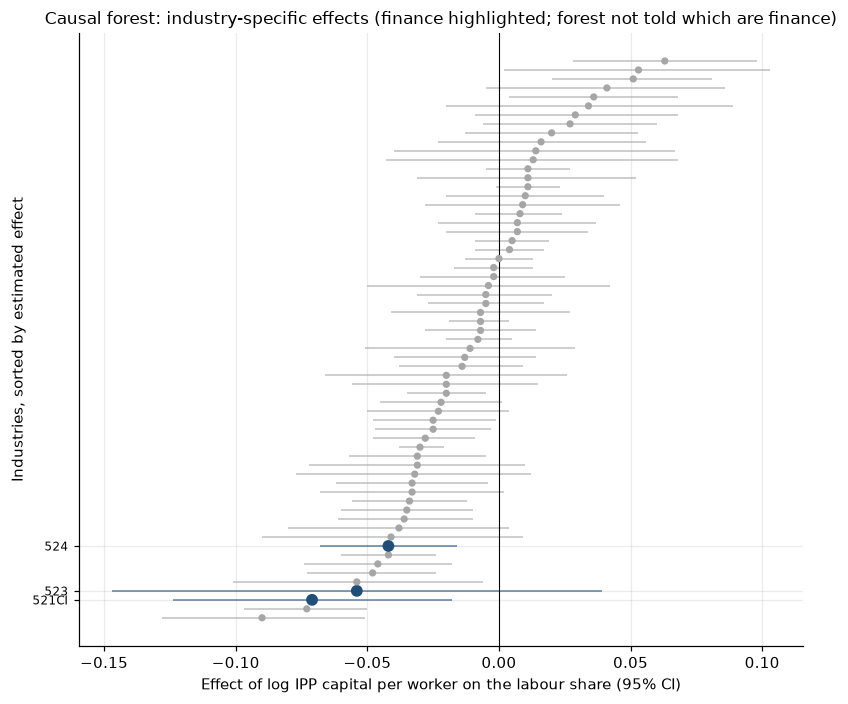

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
y = np.arange(len(ind))
cols = np.where(ind.finance == 1, st.PALETTE["finance"], st.PALETTE["other"])
ax.hlines(y, ind.ci_low, ind.ci_high, color=cols, lw=1, alpha=0.7)
ax.scatter(ind.cate, y, c=cols, s=np.where(ind.finance == 1, 45, 14), zorder=3)
ax.axvline(0, color="k", lw=0.7)
ax.set_yticks(y[ind.finance == 1]); ax.set_yticklabels(ind.loc[ind.finance == 1, "code"], fontsize=8)
ax.set_xlabel("Effect of log IPP capital per worker on the labour share (95% CI)")
ax.set_ylabel("Industries, sorted by estimated effect")
ax.set_title("Causal forest: industry-specific effects (finance highlighted; forest not told which are finance)")
st.savefig(fig, "fig15_cf_industry_effects"); plt.show()

### Is finance's position unusual? Rank test
Compares the finance industries' average estimated effect with that of 10,000 random groups of the same size.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
k = int(ind.finance.sum())
fin_mean = ind.loc[ind.finance == 1, "cate"].mean()
rand = np.array([ind["cate"].sample(k, random_state=int(rng.integers(1e9))).mean() for _ in range(10000)])
p_rank = (np.sum(rand <= fin_mean) + 1) / (len(rand) + 1)
cf_test = pd.Series({"finance_mean_effect": fin_mean, "other_mean_effect": ind.loc[ind.finance == 0, "cate"].mean(),
                     "finance_mean_rank": ind.loc[ind.finance == 1, "rank"].mean(), "n_industries": len(ind),
                     "one_sided_p_rank_test": p_rank,
                     "share_finance_with_ci_below_zero": (ind.loc[ind.finance == 1, "ci_high"] < 0).mean(),
                     "share_other_with_ci_below_zero": (ind.loc[ind.finance == 0, "ci_high"] < 0).mean()})
cf_test.to_frame("value").to_csv(st.TABLES_DIR / "cf_finance_rank_test.csv")
cf_test.round(4)

finance_mean_effect                 -0.0557
other_mean_effect                   -0.0086
finance_mean_rank                    5.3333
n_industries                        63.0000
one_sided_p_rank_test                0.0052
share_finance_with_ci_below_zero     0.6667
share_other_with_ci_below_zero       0.2667
dtype: float64

## A4. What drives the heterogeneity?
Feature importance in the forest, and a depth-2 tree that summarises which initial characteristics separate labour-substituting from labour-neutral industries.

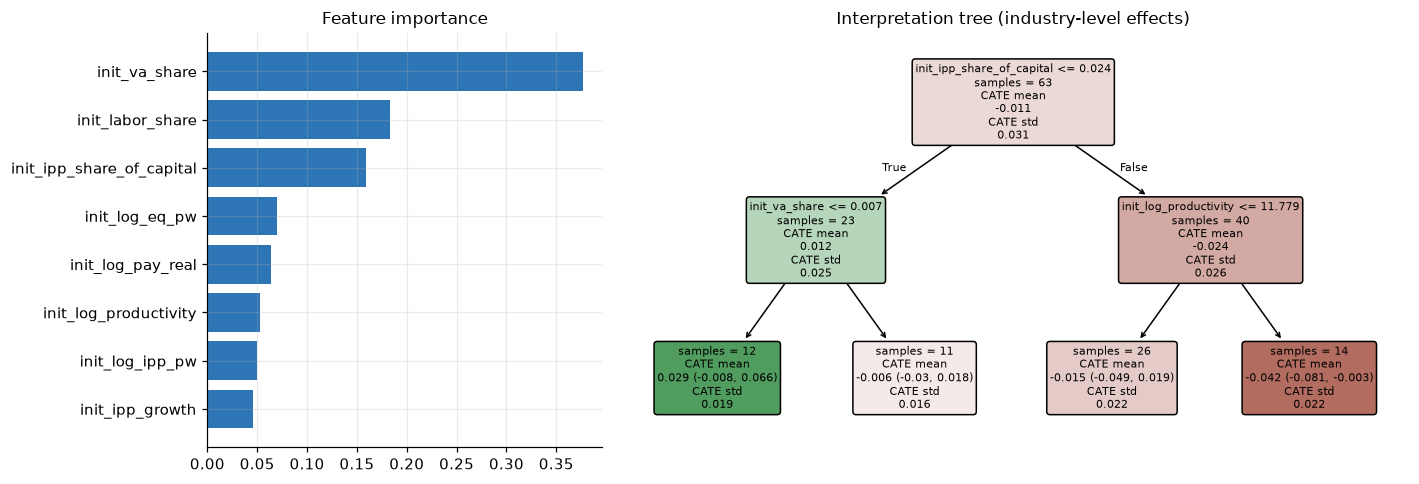

init_va_share                0.3770
init_labor_share             0.1827
init_ipp_share_of_capital    0.1593
init_log_eq_pw               0.0696
init_log_pay_real            0.0636
init_log_productivity        0.0523
init_log_ipp_pw              0.0495
init_ipp_growth              0.0460
dtype: float64

In [8]:
imp = pd.Series(cf.feature_importances_, index=X_COLS).sort_values(ascending=False)
st.save_table(imp.to_frame("importance").round(4), "cf_feature_importance", caption="Causal forest feature importance")
from econml.cate_interpreter import SingleTreeCateInterpreter
intrp = SingleTreeCateInterpreter(include_model_uncertainty=True, max_depth=2, min_samples_leaf=8)
intrp.interpret(cf, ind[X_COLS].values)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2]})
axes[0].barh(imp.index[::-1], imp.values[::-1], color=st.PALETTE["accent"]); axes[0].set_title("Feature importance")
plt.sca(axes[1]); intrp.plot(feature_names=X_COLS, fontsize=7); axes[1].set_title("Interpretation tree (industry-level effects)")
st.savefig(fig, "fig16_cf_drivers"); plt.show()
imp.round(4)

# Part B · Forecasting labour-share changes (H4)
## B1. Setup

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, HuberRegressor, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

df["d_log_ipp_pw"] = g["log_ipp_pw"].diff()
FEATURES = [c for c in ["labor_share", "d_labor_share", "log_ipp_pw", "d_log_ipp_pw", "log_eq_pw", "ipp_share_of_capital",
                        "g_ipp_stock", "g_productivity", "prod_pay_gap", "va_share_of_total", "finance", "information",
                        "fedfunds", "dgs10", "baa_spread", "vix", "nasdaq_ret", "ecom_share", "recession",
                        "log_business_apps"] if c in df]

def models():
    m = {"Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
         "Huber": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), HuberRegressor(epsilon=1.35, alpha=1e-3, max_iter=2000)),
         "RandomForest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(
             n_estimators=500, min_samples_leaf=10, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1)),
         "HistGB_L1": HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.03,
                                                    max_leaf_nodes=8, min_samples_leaf=20, random_state=RANDOM_STATE)}
    if HAS_LGB:
        m["LightGBM_Huber"] = lgb.LGBMRegressor(objective="huber", alpha=0.02, n_estimators=300, learning_rate=0.03,
                                                num_leaves=8, min_child_samples=20, subsample=0.8, subsample_freq=1,
                                                colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)
    return m
print(len(FEATURES), "features:", FEATURES)

20 features: ['labor_share', 'd_labor_share', 'log_ipp_pw', 'd_log_ipp_pw', 'log_eq_pw', 'ipp_share_of_capital', 'g_ipp_stock', 'g_productivity', 'prod_pay_gap', 'va_share_of_total', 'finance', 'information', 'fedfunds', 'dgs10', 'baa_spread', 'vix', 'nasdaq_ret', 'ecom_share', 'recession', 'log_business_apps']


## B2. Expanding-window evaluation at 1- and 3-year horizons
For forecast origin *T* and horizon *h*, models are trained only on rows whose outcome (year *t+h*) was known by *T*, so there is no look-ahead.

In [10]:
def evaluate(h, first_origin=2008):
    d = df.copy()
    d["target"] = d.groupby("code")["labor_share"].shift(-h) - d["labor_share"]
    d = d.dropna(subset=["target", "log_ipp_pw", "labor_share"])
    preds = []
    for T in sorted(d.year.unique()):
        if T < first_origin:
            continue
        train, test = d[d.year <= T - h], d[d.year == T]
        if len(test) == 0 or len(train) < 200:
            continue
        lo, hi = train["target"].quantile([0.01, 0.99])
        y_tr = train["target"].clip(lo, hi)
        out = test[["code", "year", "finance", "target"]].copy()
        out["target_capped"] = out["target"].clip(lo, hi)
        out["ZeroChange"], out["HistMean"] = 0.0, y_tr.mean()
        for name, m in models().items():
            m.fit(train[FEATURES], y_tr)
            out[name] = m.predict(test[FEATURES])
        preds.append(out)
    return pd.concat(preds, ignore_index=True)

def score(P, h):
    names = [c for c in P.columns if c not in ["code", "year", "finance", "target", "target_capped"]]
    rows = {}
    for m in names:
        e, ec = P["target"] - P[m], P["target_capped"] - P[m]
        rows[m] = {"RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.mean(np.abs(e)), "MAE_capped": np.mean(np.abs(ec)),
                   "R2_oos_vs_histmean": 1 - (e ** 2).sum() / ((P["target"] - P["HistMean"]) ** 2).sum()}
        if m != "ZeroChange":
            dm = st.diebold_mariano(P["target"] - P["ZeroChange"], e, h=h, power=1)   # absolute-error loss
            rows[m]["DM_vs_ZeroChange_MAE"], rows[m]["p_DM"] = dm["DM"], dm["p"]
    return pd.DataFrame(rows).T

results, P_by_h = {}, {}
for h in [1, 3]:
    P_by_h[h] = evaluate(h)
    results[h] = score(P_by_h[h], h)
    st.save_table(results[h].round(4), f"h4_oos_h{h}", caption=f"H4: out-of-sample accuracy, {h}-year horizon")
    print(f"\n=== Horizon {h} year(s): {len(P_by_h[h])} forecasts, origins {P_by_h[h].year.min()}-{P_by_h[h].year.max()}")
    display(results[h].round(4))


=== Horizon 1 year(s): 1088 forecasts, origins 2008-2024


,RMSE,MAE,MAE_capped,R2_oos_vs_histmean,DM_vs_ZeroChange_MAE,p_DM
ZeroChange,0.0542,0.0210,0.0186,-0.0010,NaN,NaN
HistMean,0.0542,0.0211,0.0188,0.0000,-1.7566,0.0793
Ridge,0.0537,0.0218,0.0195,0.0198,-3.9586,0.0001
Huber,0.0519,0.0216,0.0192,0.0820,-2.4556,0.0142
RandomForest,0.0532,0.0213,0.0190,0.0386,-1.5563,0.1199
HistGB_L1,0.0534,0.0212,0.0188,0.0290,-1.1374,0.2556
LightGBM_Huber,0.0532,0.0212,0.0188,0.0363,-0.9394,0.3477



=== Horizon 3 year(s): 960 forecasts, origins 2008-2022


,RMSE,MAE,MAE_capped,R2_oos_vs_histmean,DM_vs_ZeroChange_MAE,p_DM
ZeroChange,0.0591,0.0316,0.0298,0.0070,NaN,NaN
HistMean,0.0594,0.0329,0.0310,0.0000,-3.2774,0.0011
Ridge,0.0572,0.0371,0.0354,0.0726,-5.9032,0.0000
Huber,0.0586,0.0384,0.0367,0.0253,-6.2311,0.0000
RandomForest,0.0557,0.0325,0.0307,0.1189,-1.6134,0.1070
HistGB_L1,0.0561,0.0324,0.0305,0.1079,-1.2572,0.2090
LightGBM_Huber,0.0571,0.0325,0.0307,0.0734,-1.7341,0.0832


In [11]:
fin_scores = {h: score(P_by_h[h][P_by_h[h].finance == 1], h) for h in [1, 3]}
for h in [1, 3]:
    st.save_table(fin_scores[h].round(4), f"h4_oos_h{h}_finance", caption=f"H4: finance industries, {h}-year horizon")
    print(f"Finance industries, horizon {h}:"); display(fin_scores[h][["RMSE", "MAE", "R2_oos_vs_histmean"]].round(4))

Finance industries, horizon 1:


,RMSE,MAE,R2_oos_vs_histmean
ZeroChange,0.1867,0.0609,-0.0033
HistMean,0.1864,0.0603,0.0000
Ridge,0.1838,0.0635,0.0276
Huber,0.1760,0.0601,0.1093
RandomForest,0.1833,0.0620,0.0339
HistGB_L1,0.1853,0.0615,0.0124
LightGBM_Huber,0.1846,0.0617,0.0194


Finance industries, horizon 3:


,RMSE,MAE,R2_oos_vs_histmean
ZeroChange,0.1629,0.0699,-0.0380
HistMean,0.1599,0.0679,0.0000
Ridge,0.1261,0.0629,0.3775
Huber,0.1259,0.0625,0.3796
RandomForest,0.1442,0.0628,0.1868
HistGB_L1,0.1493,0.0628,0.1275
LightGBM_Huber,0.1526,0.0635,0.0887


## B3. Classification: will the labour share be lower in 3 years?

In [12]:
d3 = df.copy()
d3["down3"] = (d3.groupby("code")["labor_share"].shift(-3) < d3["labor_share"]).astype(float)
d3.loc[d3.groupby("code")["labor_share"].shift(-3).isna(), "down3"] = np.nan
d3 = d3.dropna(subset=["down3", "log_ipp_pw"])
cp = []
for T in sorted(d3.year.unique()):
    if T < 2008:
        continue
    train, test = d3[d3.year <= T - 3], d3[d3.year == T]
    if len(test) == 0 or train.down3.nunique() < 2:
        continue
    out = test[["code", "year", "down3"]].copy()
    out["BaseRate"] = train.down3.mean()
    for name, m in {"Logit": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.5, max_iter=3000)),
                    "RandomForest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(
                        n_estimators=500, min_samples_leaf=10, max_features=0.5, random_state=RANDOM_STATE, n_jobs=-1))}.items():
        m.fit(train[FEATURES], train.down3.astype(int))
        out[name] = m.predict_proba(test[FEATURES])[:, 1]
    cp.append(out)
C = pd.concat(cp, ignore_index=True)
cls = pd.DataFrame({m: {"AUC": roc_auc_score(C.down3, C[m]) if C[m].nunique() > 1 else 0.5,
                        "Brier": brier_score_loss(C.down3, C[m])} for m in ["BaseRate", "Logit", "RandomForest"]}).T
st.save_table(cls.round(4), "h4_classification_h3", caption="Classification of 3-year labour-share declines")
cls.round(4)

,AUC,Brier
BaseRate,0.4451,0.2551
Logit,0.5003,0.2988
RandomForest,0.4936,0.2661


## B4. What drives the 3-year forecasts? (SHAP)
SHAP values describe the fitted model. They are only informative about the data if the model forecasts better than the benchmarks in B2.

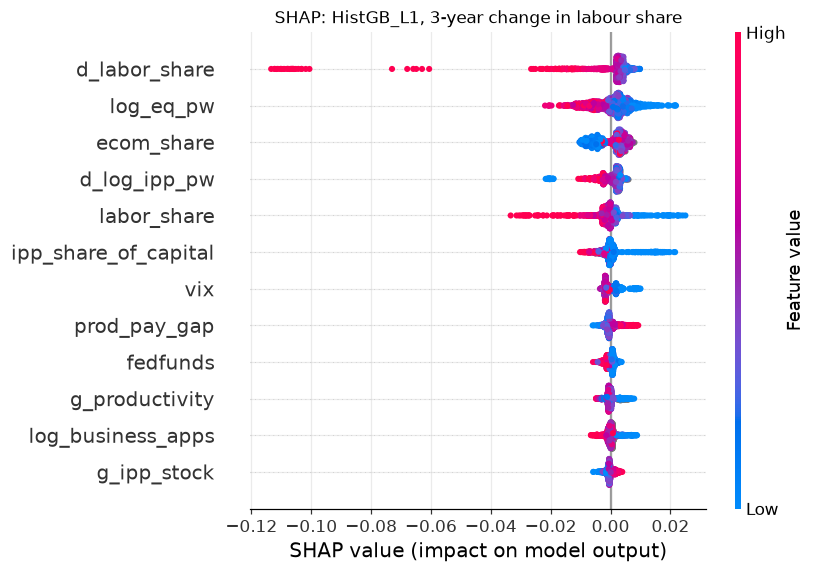

,mean_abs_shap,rank
d_labor_share,0.00607,1
log_eq_pw,0.00480,2
ecom_share,0.00432,3
d_log_ipp_pw,0.00270,4
labor_share,0.00261,5
ipp_share_of_capital,0.00213,6
vix,0.00188,7
prod_pay_gap,0.00142,8
fedfunds,0.00103,9
g_productivity,0.00102,10


In [13]:
import shap
h = 3
tree_names = [m for m in ["LightGBM_Huber", "HistGB_L1", "RandomForest"] if m in results[h].index]
best = results[h].loc[tree_names, "MAE"].idxmin()
d = df.copy(); d["target"] = d.groupby("code")["labor_share"].shift(-h) - d["labor_share"]
d = d.dropna(subset=["target", "log_ipp_pw", "labor_share"])
lo, hi = d["target"].quantile([0.01, 0.99])
mdl = models()[best]
if best == "RandomForest":
    imp_ = SimpleImputer(strategy="median").fit(d[FEATURES]); Xs = pd.DataFrame(imp_.transform(d[FEATURES]), columns=FEATURES)
    mdl = mdl.steps[-1][1].fit(Xs, d["target"].clip(lo, hi))
else:
    Xs = d[FEATURES]; mdl.fit(Xs, d["target"].clip(lo, hi))
sv = shap.TreeExplainer(mdl).shap_values(Xs)
shap.summary_plot(sv, Xs, show=False, max_display=12)
fig = plt.gcf(); fig.set_size_inches(7.5, 5); plt.title(f"SHAP: {best}, 3-year change in labour share")
st.savefig(fig, "fig17_shap_h3"); plt.show()
shap_tab = pd.DataFrame({"mean_abs_shap": np.abs(sv).mean(axis=0)}, index=FEATURES).sort_values("mean_abs_shap", ascending=False)
shap_tab["rank"] = range(1, len(shap_tab) + 1)
st.save_table(shap_tab.round(5), "h4_shap_h3", caption="Mean |SHAP|, 3-year horizon")
shap_tab.head(10).round(5)

## Summary for the paper

In [14]:
summary = {}
for h in [1, 3]:
    r = results[h]
    ml = [m for m in r.index if m not in ("ZeroChange", "HistMean")]
    bm = r.loc[ml, "MAE"].idxmin()
    summary[f"H4 best model, {h}y"] = bm
    summary[f"H4 MAE gain vs zero-change, {h}y (%)"] = round(100 * (1 - r.loc[bm, "MAE"] / r.loc["ZeroChange", "MAE"]), 2)
    summary[f"H4 DM p-value, {h}y"] = round(r.loc[bm, "p_DM"], 4)
    summary[f"H4 supported, {h}y"] = bool(r.loc[bm, "MAE"] < r.loc["ZeroChange", "MAE"] and r.loc[bm, "p_DM"] < 0.05 and r.loc[bm, "DM_vs_ZeroChange_MAE"] > 0)
summary["3y classification AUC (best)"] = round(cls.loc[["Logit", "RandomForest"], "AUC"].max(), 4)
summary["CF average effect"] = round(ate["point_estimate"].iloc[0], 4)
summary["CF finance mean effect"] = round(fin_mean, 4)
summary["CF finance mean rank (of %d)" % len(ind)] = round(ind.loc[ind.finance == 1, "rank"].mean(), 1)
summary["CF rank-test one-sided p"] = round(p_rank, 4)
out = pd.Series(summary)
out.to_frame("value").to_csv(st.TABLES_DIR / "ml_summary.csv")
out

H4 best model, 1y                     LightGBM_Huber
H4 MAE gain vs zero-change, 1y (%)             -0.95
H4 DM p-value, 1y                             0.3477
H4 supported, 1y                               False
H4 best model, 3y                          HistGB_L1
H4 MAE gain vs zero-change, 3y (%)             -2.37
H4 DM p-value, 3y                              0.209
H4 supported, 3y                               False
3y classification AUC (best)                  0.5003
CF average effect                            -0.0109
CF finance mean effect                       -0.0557
CF finance mean rank (of 63)                     5.3
CF rank-test one-sided p                      0.0052
dtype: object